# Figure 4B

In [11]:
from riskhistory.format import rcParams
from riskhistory.data import (
    load_pupiltimeseries_avgpred,
    load_pupiltimeseries_contrasts,
    load_pupilbetas_choicealteration_avgpred,
    load_pupilbetas_choicealteration_contrasts,
    DATASET_LABELS,
)
import numpy as np
import matplotlib.pyplot as plt

DATASETS = ["equalIndifference", "equalRange", "sheng2020"]

### Helper functions

In [25]:
# ----- shared -----
def sig_stars(p):
    if p < 0.001:
        return "***"
    if p < 0.01:
        return "**"
    if p < 0.05:
        return "*"
    return "n.s."


def add_significance_bracket(ax, x1, x2, y, h, p):
    ax.plot([x1, x1, x2, x2], [y, y + h, y + h, y], color="black", linewidth=1.2)
    ax.text((x1 + x2) / 2, y + h, sig_stars(p), ha="center", va="bottom")


# ----- Row A: pupil dilation timeseries by transition -----
# AA/AR/RA/RR = (previous choice, current choice)
TRANSITION_SHORT = {
    "accept_to_accept": "A-A",
    "accept_to_reject": "A-R",
    "reject_to_accept": "R-A",
    "reject_to_reject": "R-R",
}
TRANSITION_COLORS = {
    "accept_to_accept": "#8C0000",
    "accept_to_reject": "#008C59",
    "reject_to_accept": "#DCC200",
    "reject_to_reject": "#291B85",
}
# Each group is its own panel: the 2 transition levels being compared --
# (RA vs AA) for current choice = accept, (AR vs RR) for current = reject.
ROW_A_GROUPS = [
    ("reject_to_accept", "accept_to_accept"),
    ("accept_to_reject", "reject_to_reject"),
]
ROW_A_CONDITION_LABELS = ["Accept trials", "Reject trials"]


def get_contrast_pvalues(contrasts_df, dataset, label_a, label_b, p_col="p_adj_bh"):
    """Per-timebin values of p_col (sorted by timebin) for one transition
    contrast; contrast labels are 'A - B', try both orderings."""
    ds_df = contrasts_df[contrasts_df["dataset"] == dataset]
    for cand in (f"{label_a} - {label_b}", f"{label_b} - {label_a}"):
        sub = ds_df[ds_df["contrast"] == cand]
        if len(sub):
            sub = sub.sort_values("timebin")
            return sub["timebin"].values, sub[p_col].values
    raise KeyError(f"No contrast found for {label_a} vs {label_b}")


def plot_pupil_timeseries_panel(ax, ds_avgpred, ds_contrasts, dataset,
                                higher_label, lower_label, condition_label,
                                show_ylabel=False, show_dataset_label=False,
                                show_sig_note=False, show_xlabel=False):
    """Adjusted pupil size over time for two transition levels, with a
    black line at y=-0.5 marking timepoints where higher_label vs
    lower_label is significant (BH-adjusted, light gray where not)."""
    for level in (higher_label, lower_label):
        level_emm = ds_avgpred[ds_avgpred["transition"] == level].sort_values("timebin")
        color = TRANSITION_COLORS[level]
        ax.plot(level_emm["timebin"], level_emm["avgpred"], color=color,
               linewidth=8, label=TRANSITION_SHORT[level])
        ax.fill_between(level_emm["timebin"], level_emm["asymp.LCL"],
                        level_emm["asymp.UCL"], color=color, alpha=0.15)

    ax.axhline(0, color="#aaaaaa", linewidth=2, linestyle="--", zorder=1)
    ax.set_ylim(-0.6, 0.8)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.legend(loc="upper left", frameon=True)
    if show_ylabel:
        ax.set_ylabel("Adjusted mean pupil size")
    if show_dataset_label:
        ax.set_title(f"   {DATASET_LABELS[dataset]}\n", va="top", ha="left")
    if show_xlabel:
        ax.set_xlabel("Time since start of the trial (sec)", loc = "left")

    ax.text(0.50, 1.03, condition_label, transform=ax.transAxes,
           ha="center", va="top", fontsize=14, fontweight="bold")

    timebins, pvals = get_contrast_pvalues(ds_contrasts, dataset, higher_label, lower_label)
    sig_line = np.where(pvals < 0.05, -0.5, np.nan)
    ax.axhline(-0.5, color="#dddddd", linewidth=2, zorder=1)
    ax.plot(timebins, sig_line, color="black", linewidth=3, zorder=3)
    if show_sig_note:
        ax.text(0.02, -0.50, "Contrast adj. p < 0.05", transform=ax.get_yaxis_transform(),
               ha="left", va="bottom", fontsize=14, color="black")


# ----- Row C: pupil response by choice alteration category -----
# Separate light-to-dark ramps for Accept vs Reject, so the two choice
# types are visually distinguishable in addition to the Low/Medium/High
# alteration level.
CHOICEALT_BASE_COLORS_ACCEPT = {
    "Low": "#8C0000",
    "Medium": "#F8650C",
    "High": "#DCC200",
}
CHOICEALT_BASE_COLORS_REJECT = {
    "Low": "#291B85",
    "Medium": "#197A89",
    "High": "#008C59",
}
CHOICEALT_CATEGORY_ORDER = ["Low_Accept", "Medium_Accept", "High_Accept",
                            "Low_Reject", "Medium_Reject", "High_Reject"]
CHOICEALT_GROUP_PALETTES = {
    "Accept": CHOICEALT_BASE_COLORS_ACCEPT,
    "Reject": CHOICEALT_BASE_COLORS_REJECT,
}
CHOICEALT_COLORS = {}
for cat in CHOICEALT_CATEGORY_ORDER:
    level, group = cat.split("_")
    CHOICEALT_COLORS[cat] = CHOICEALT_GROUP_PALETTES[group][level]

# (label_a, label_b, tier): within-group only (accept vs accept, reject vs
# reject). tier 0 = adjacent pairs, tier 1 = full-span pair, so brackets
# stack cleanly within each group.
CHOICEALT_BRACKET_SPECS = [
    ("Low_Accept", "Medium_Accept", 0),
    ("Medium_Accept", "High_Accept", 0),
    ("Low_Accept", "High_Accept", 1),
    ("Low_Reject", "Medium_Reject", 0),
    ("Medium_Reject", "High_Reject", 0),
    ("Low_Reject", "High_Reject", 1),
]

# Extra x-axis gap between the Accept and Reject groups of 3 bars.
CHOICEALT_GROUP_GAP = 0.8
CHOICEALT_X_POSITIONS = {}
_pos = 0.0
for _i, _cat in enumerate(CHOICEALT_CATEGORY_ORDER):
    if _i == 3:
        _pos += CHOICEALT_GROUP_GAP
    CHOICEALT_X_POSITIONS[_cat] = _pos
    _pos += 1


def get_choicealteration_contrast(contrasts_df, label_a, label_b):
    """label_a/label_b are e.g. 'Low_Accept'/'Medium_Accept' (must share a
    group suffix). Contrast labels in the CSV are 'A - B (Group)'; try both
    orderings."""
    base_a, group_a = label_a.rsplit("_", 1)
    base_b, group_b = label_b.rsplit("_", 1)
    assert group_a == group_b, f"{label_a} and {label_b} must share a group"
    for cand in (f"{base_a} - {base_b} ({group_a})", f"{base_b} - {base_a} ({group_a})"):
        match = contrasts_df[contrasts_df["contrast"] == cand]
        if len(match):
            return match.iloc[0]
    raise KeyError(f"No contrast found for {label_a} vs {label_b}")


def plot_choice_alteration_panel(ax, ds_avgpred, ds_contrasts, dataset,
                                 show_ylabel=False, show_xlabel=False):
    """avg_predictions() (points) for the 6 choice-alteration x accept/reject
    categories, with significance brackets for the 6 within-type
    avg_comparisons()."""
    x_pos = np.array([CHOICEALT_X_POSITIONS[cat] for cat in CHOICEALT_CATEGORY_ORDER])
    means, los, his = [], [], []
    for cat in CHOICEALT_CATEGORY_ORDER:
        row = ds_avgpred[ds_avgpred["choice_alteration_combo"] == cat].iloc[0]
        means.append(row["avgpred"])
        los.append(row["asymp.LCL"])
        his.append(row["asymp.UCL"])
    means, los, his = np.array(means), np.array(los), np.array(his)
    yerr = [means - los, his - means]
    colors = [CHOICEALT_COLORS[cat] for cat in CHOICEALT_CATEGORY_ORDER]

    for i in range(len(CHOICEALT_CATEGORY_ORDER)):
        ax.errorbar(x_pos[i], means[i], yerr=[[yerr[0][i]], [yerr[1][i]]],
                   fmt="o", color=colors[i], markersize=20,
                   ecolor=colors[i], elinewidth=2, capsize=8, zorder=2)

    y_top, y_bottom = his.max(), los.min()
    y_range = y_top - y_bottom
    bracket_h = 0.007 * y_range
    max_tier = max(tier for _, _, tier in CHOICEALT_BRACKET_SPECS)
    tier_gap = 0.2
    for label_a, label_b, tier in CHOICEALT_BRACKET_SPECS:
        row = get_choicealteration_contrast(ds_contrasts, label_a, label_b)
        p_val = row["p_adj_bh"]
        x1, x2 = sorted([CHOICEALT_X_POSITIONS[label_a], CHOICEALT_X_POSITIONS[label_b]])
        x1 += 0.05
        x2 -= 0.05
        y_bracket = y_top + (0.02 + tier_gap * tier) * y_range
        add_significance_bracket(ax, x1, x2, y_bracket, bracket_h, p_val)

    ylim_top = y_top + (0.15 + tier_gap * max_tier + 0.15) * y_range + 2 * bracket_h
    ax.set_ylim(y_bottom - 0.1 * y_range, ylim_top)
    ax.set_title(f"{DATASET_LABELS[dataset]}", va="top")
    ax.set_xticks(x_pos)
    ax.set_xticklabels([cat.split("_")[0] for cat in CHOICEALT_CATEGORY_ORDER])
    ax.set_xlim(CHOICEALT_X_POSITIONS[CHOICEALT_CATEGORY_ORDER[0]] - 0.6,
               CHOICEALT_X_POSITIONS[CHOICEALT_CATEGORY_ORDER[-1]] + 0.6)
    ax.axhline(0, color="#aaaaaa", linewidth=0.8, linestyle="--", zorder=1)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    accept_center = (CHOICEALT_X_POSITIONS["Low_Accept"] + CHOICEALT_X_POSITIONS["High_Accept"]) / 2
    reject_center = (CHOICEALT_X_POSITIONS["Low_Reject"] + CHOICEALT_X_POSITIONS["High_Reject"]) / 2
    ax.text(accept_center, -0.1, "Accept trials", transform=ax.get_xaxis_transform(),
           ha="center", va="top")
    ax.text(reject_center, -0.1, "Reject trials", transform=ax.get_xaxis_transform(),
           ha="center", va="top")

    if show_xlabel:
        ax.set_xlabel("Degree of choice-history deviation", labelpad=30)
    if show_ylabel:
        ax.set_ylabel("Adjusted mean of\ndecision-related pupil metric")

### Figure 4: 3 rows x 3 datasets
Row B is reserved blank space for a panel assembled elsewhere (not generated here). Row A: predicted pupil size over time by transition (start-aligned), split into 6 panels (3 datasets x 2 current-choice groups). Row C: pupil response by choice alteration category, nested by choice type (same plot as `figure7.ipynb`). Columns align by dataset -- each Row C panel spans the same width as its dataset's 2 Row A panels.

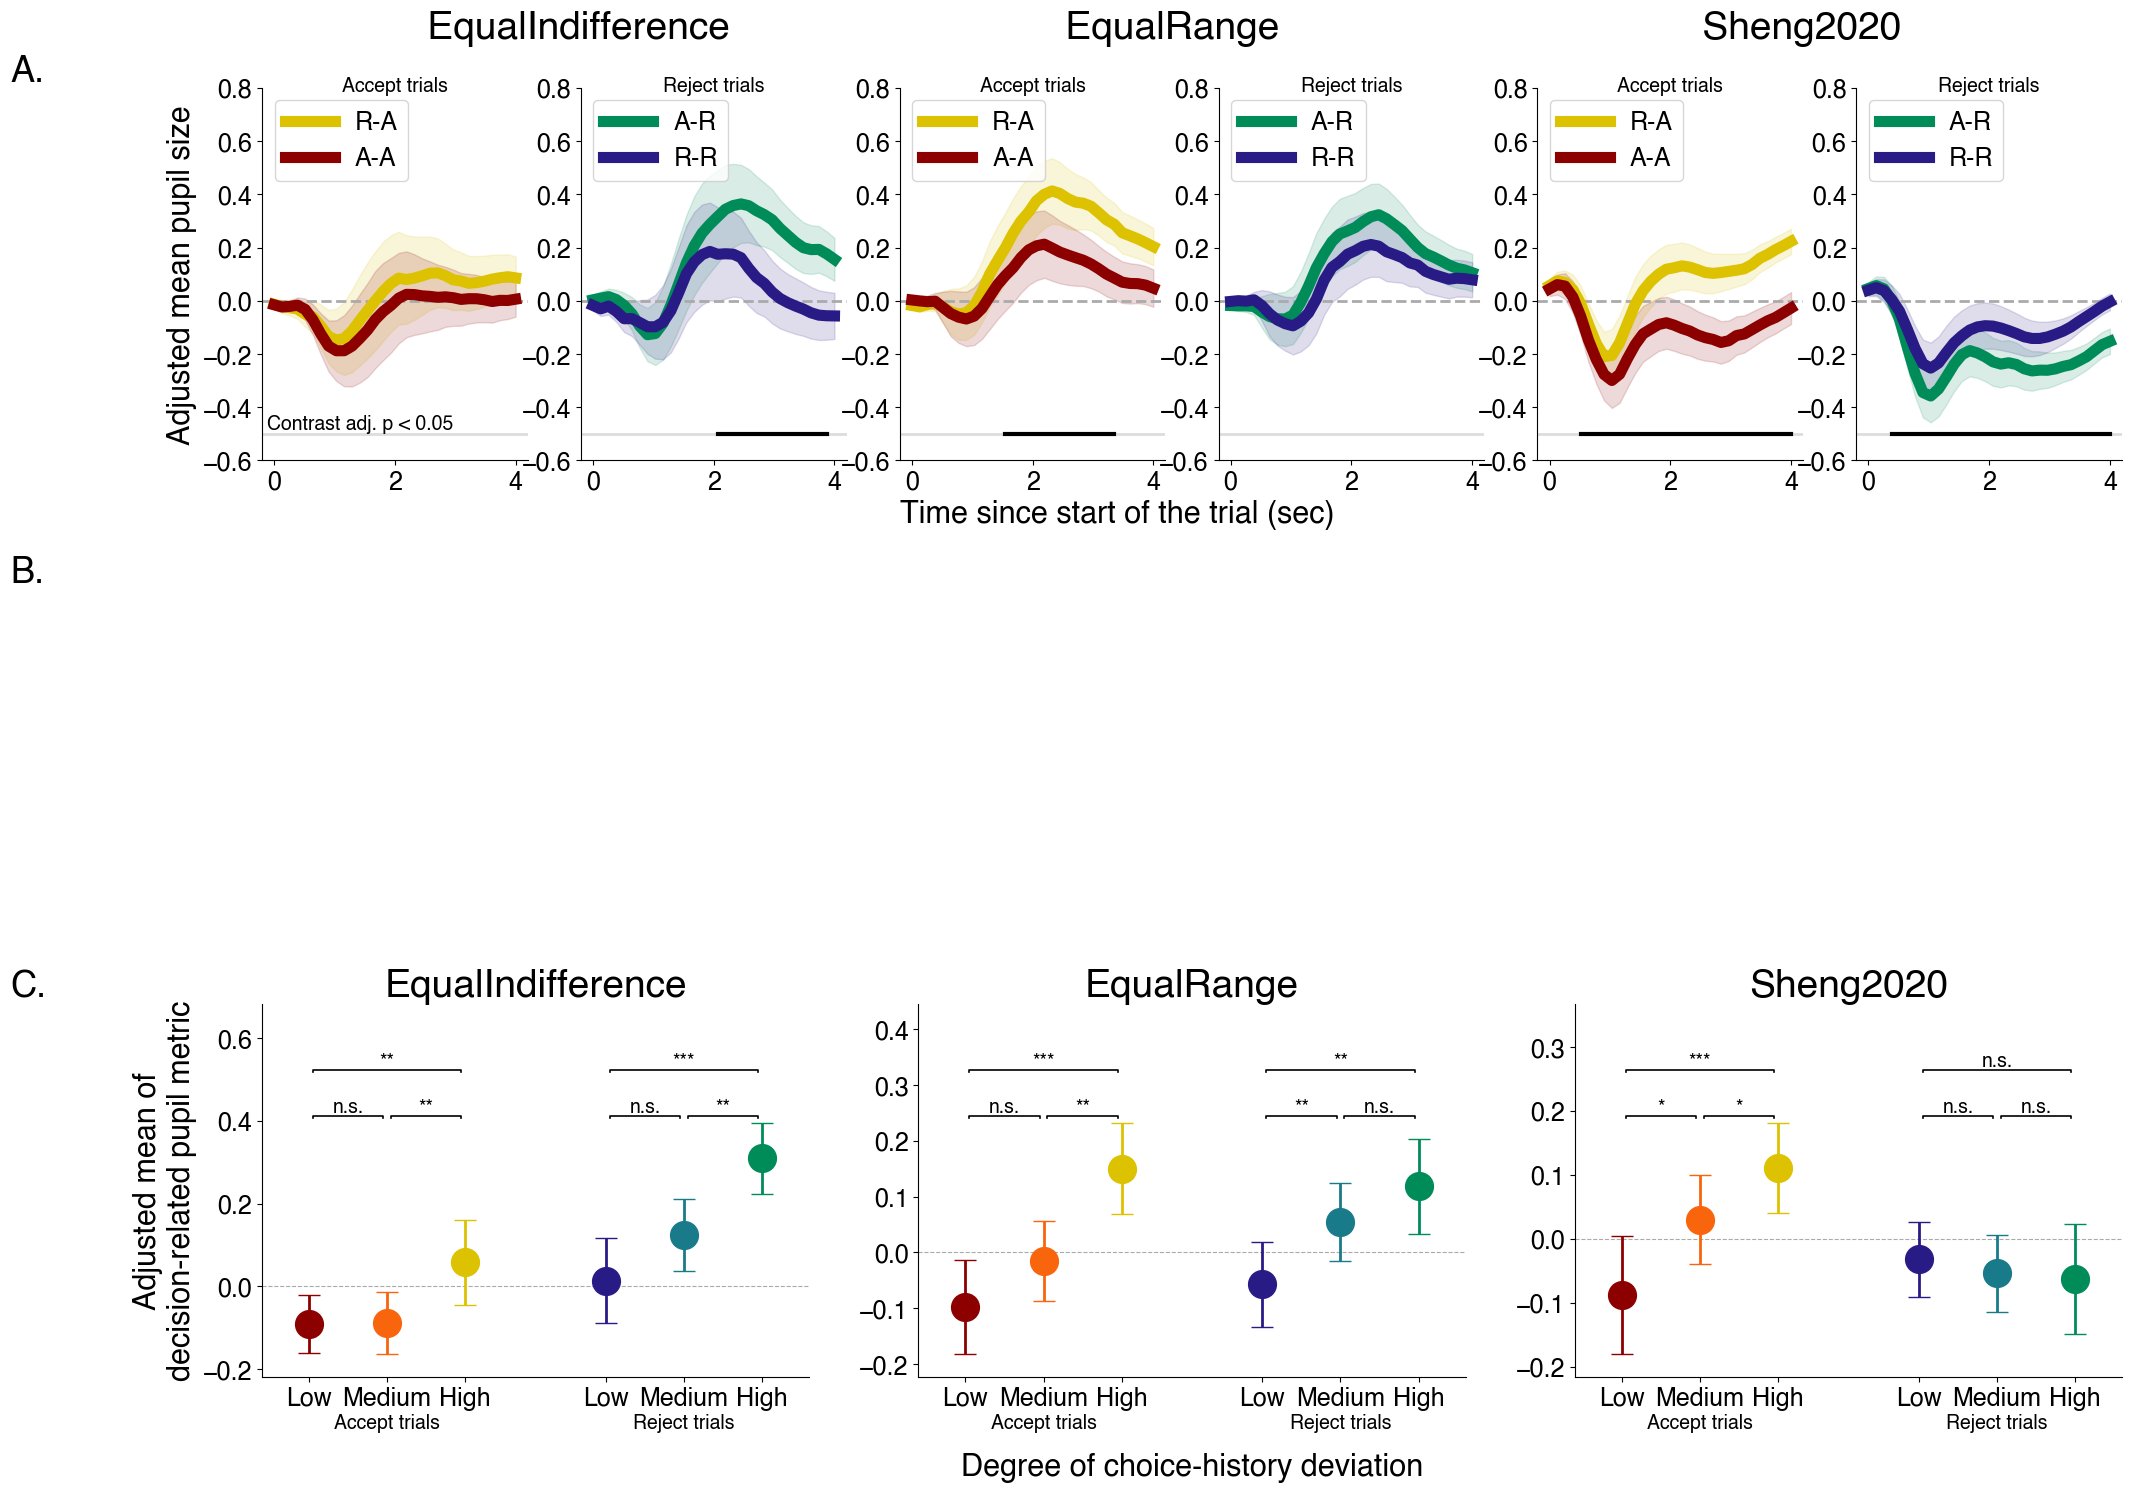

In [26]:
avgpred_start = load_pupiltimeseries_avgpred(alignment="start")
contrasts_start = load_pupiltimeseries_contrasts(alignment="start")
choicealt_avgpred = load_pupilbetas_choicealteration_avgpred()
choicealt_contrasts = load_pupilbetas_choicealteration_contrasts()

n_groups = len(ROW_A_GROUPS)
ncols_a = len(DATASETS) * n_groups

# 3 rows: A = pupil timeseries; B = reserved blank space for a panel
# assembled elsewhere; C = choice alteration.
fig = plt.figure(figsize=(24, 14))
subfig_a, subfig_b, subfig_c = fig.subfigures(
    nrows=3, ncols=1, height_ratios=[5, 4, 5], hspace=0.05
)

axes_a = subfig_a.subplots(nrows=1, ncols=ncols_a)

for ds_idx, ds in enumerate(DATASETS):
    ds_avgpred = avgpred_start[avgpred_start["dataset"] == ds]

    for grp_idx, (higher_label, lower_label) in enumerate(ROW_A_GROUPS):
        col = ds_idx * n_groups + grp_idx
        plot_pupil_timeseries_panel(
            axes_a[col], ds_avgpred, contrasts_start, ds,
            higher_label, lower_label, ROW_A_CONDITION_LABELS[grp_idx],
            show_ylabel=(col == 0),
            show_dataset_label=(grp_idx == 0),
            show_sig_note=(col == 0),
            show_xlabel=(ds_idx == 1 and grp_idx == 0),
        )

axes_c = subfig_c.subplots(nrows=1, ncols=len(DATASETS))

for col, ds in enumerate(DATASETS):
    ds_avgpred = choicealt_avgpred[choicealt_avgpred["dataset"] == ds]
    ds_contrasts = choicealt_contrasts[choicealt_contrasts["dataset"] == ds]
    plot_choice_alteration_panel(axes_c[col], ds_avgpred, ds_contrasts, ds,
                                 show_ylabel=(col == 0), show_xlabel=(col == 1))

# Row labels, placed just outside the top-left corner of each row's leftmost
# panel (same convention as figure1.ipynb's "A."/"B."/"C."). B. marks the
# reserved blank row; A., C. label the plots generated here.
for subfig, label in [(subfig_a, "A."), (subfig_b, "B."), (subfig_c, "C.")]:
    subfig.text(0.02, 0.95, label, transform=subfig.transSubfigure,
               fontsize=26, fontweight="bold", va="top", ha="left")

fig.savefig("saved/figure4_B.svg", dpi=300, bbox_inches="tight")
plt.show()

### Statistics

#### Pupil time series contrasts

In [10]:
for dataset in DATASETS:
    print(dataset)
    print("R-A > A-A")
    timebins = contrasts_start.query(f"contrast == 'reject_to_accept - accept_to_accept' & dataset == '{dataset}' & p_adj_bh < 0.05 & estimate > 0").sort_values("timebin")["timebin"].values
    if len(timebins) > 0:
        print("From:", timebins[0], "to", timebins[-1])
    else:
        print("Nope!")
    print("R-A < A-A")
    timebins = contrasts_start.query(f"contrast == 'reject_to_accept - accept_to_accept' & dataset == '{dataset}' & p_adj_bh < 0.05 & estimate < 0").sort_values("timebin")["timebin"].values
    if len(timebins) > 0:
        print("From:", timebins[0], "to", timebins[-1])
    else:
        print("Nope!")

    print("A-R > R-R")
    timebins = contrasts_start.query(f"contrast == 'accept_to_reject - reject_to_reject' & dataset == '{dataset}' & p_adj_bh < 0.05 & estimate > 0").sort_values("timebin")["timebin"].values
    if len(timebins) > 0:
        print("From:", timebins[0], "to", timebins[-1])
    else:
        print("Nope!")

    print("A-R < R-R")
    timebins = contrasts_start.query(f"contrast == 'accept_to_reject - reject_to_reject' & dataset == '{dataset}' & p_adj_bh < 0.05 & estimate < 0").sort_values("timebin")["timebin"].values
    if len(timebins) > 0:
        print("From:", timebins[0], "to", timebins[-1])
    else:
        print("Nope!")
    print()
    print()

equalIndifference
R-A > A-A
Nope!
R-A < A-A
Nope!
A-R > R-R
From: 2.06451612903226 to 3.87096774193548
A-R < R-R
Nope!


equalRange
R-A > A-A
From: 1.54838709677419 to 3.35483870967742
R-A < A-A
Nope!
A-R > R-R
Nope!
A-R < R-R
Nope!


sheng2020
R-A > A-A
From: 0.516129032258065 to 4.0
R-A < A-A
Nope!
A-R > R-R
Nope!
A-R < R-R
From: 0.387096774193548 to 4.0




In [8]:
for dataset in DATASETS:
    print(dataset)
    print("R-A versus A-A")
    estimates = contrasts_start.query(f"contrast == 'reject_to_accept - accept_to_accept' & dataset == '{dataset}'")["estimate"].values
    print("Mean = ", np.mean(estimates))
    
    print("A-R versus R-R")
    estimates = contrasts_start.query(f"contrast == 'accept_to_reject - reject_to_reject' & dataset == '{dataset}'")["estimate"].values
    print("Mean = ", np.mean(estimates))

    print()
    print()

equalIndifference
R-A versus A-A
Mean =  0.010033343592959125
A-R versus R-R
Mean =  0.08402019603173766


equalRange
R-A versus A-A
Mean =  0.07305913297179265
A-R versus R-R
Mean =  0.024235874781359253


sheng2020
R-A versus A-A
Mean =  0.1435137085397467
A-R versus R-R
Mean =  -0.1163546433643009


